**Load Data**

In [1]:
!pip install numpy matplotlib seaborn pandas openpyxl smogn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached smogn-0.1.2-py3-none-any.whl.metadata (4.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
   ---------------------------------------- 0.0/7.8 MB ? eta -:--:--
   ----------------- ---------------------- 3.4/7.8 MB 20.2 MB/s eta 0:00:01
   ---------------------------------------- 7.8/7.8 MB 20.2 MB/s  0:00:00
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached smogn-0.1.2-py3-none-any.whl (30 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 1.5/1.5 MB 16.3 MB/s  0:00:00
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   ------------------------------------

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
import re
import smogn
from scipy.stats import gmean
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, cross_validate, KFold, cross_val_predict, train_test_split
from sklearn.ensemble import StackingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

ModuleNotFoundError: No module named 'xgboost'

In [ ]:
wqi_data = pd.read_csv('quang_ninh_wqi_v2.csv')

In [ ]:
print("Dataset from file quang_ninh_wqi_v2:")
print(wqi_data.head())

Dataset from file quang_ninh_wqi_v2:
                                            Location Sample ID    Month  \
0  Sông Vàng Danh phía sau điểm hợp lưu với ...       NM8    Qúy I   
1  Sông Vàng Danh phía sau điểm hợp lưu với ...       NM8   Qúy II   
2  Sông Vàng Danh phía sau điểm hợp lưu với ...       NM8  Qúy III   
3  Sông Vàng Danh phía sau điểm hợp lưu với ...       NM8   Qúy IV   
4                                        Suối 12 Khe       NM9    Qúy I   

  Nhiệt độ (0C)    pH DO mg/l Salinity Turbidity TSS mg/l COD mg/l  ...  \
0          21,5   7,9    8,23      NaN       NaN     27,4      9,8  ...   
1          24,1  7,29    7,28      NaN       NaN     30,4     10,2  ...   
2          28,4  6,81    7,18      NaN       NaN     94,2     19,2  ...   
3          26,7  7,42    6,25      NaN       NaN     75,2     15,2  ...   
4          17,1  6,31    7,44      NaN       NaN     11,1      5,3  ...   

  Cr(VI) Tổng phenol Tổng hoạt độ phóng xạ α Tổng hoạt độ phó

In [ ]:
wqi_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1110 entries, 0 to 1109
Data columns (total 43 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Location                         1110 non-null   object
 1   Sample ID                        1106 non-null   object
 2   Month                            1110 non-null   object
 3   Nhiệt độ (0C)                    1110 non-null   object
 4   pH                               1110 non-null   object
 5   DO mg/l                          1110 non-null   object
 6   Salinity                         954 non-null    object
 7   Turbidity                        954 non-null    object
 8   TSS mg/l                         1110 non-null   object
 9   COD mg/l                         1110 non-null   object
 10  BOD5 mg/l                        1110 non-null   object
 11  SO42-mg/l                        156 non-null    object
 12  NO3-mg/l                         1

# 1. Data Pre-processing (25%)


---






In [ ]:
wqi_data.rename(columns={
    'Location': 'Location',
    'Sample ID': 'Sample_ID',
    'Month': 'Month',
    'Nhiệt độ (0C)': 'Temperature_C',
    'pH': 'pH',
    'DO mg/l': 'DO_mg_L',
    'Salinity': 'Salinity',
    'Turbidity': 'Turbidity',
    'TSS mg/l': 'TSS_mg_L',
    'COD mg/l': 'COD_mg_L',
    'BOD5 mg/l': 'BOD5_mg_L',
    'SO42-mg/l': 'SO4_mg_L',
    'NO3-mg/l': 'NO3_mg_L',
    'NO2-mg/l ': 'NO2_mg_L',
    'NH4+ mg/l': 'NH4_mg_L',
    'PO43- mg/l ': 'PO4_mg_L',
    'MBAS': 'MBAS',
    'Xianua': 'Cyanide',
    'Florua': 'Fluoride',
    'Cl - mg/l': 'Cl_mg_L',
    'Tổng dầu, mỡ mg/l': 'Total_Oil_Fat_mg_L',
    'Coliform MPN/100ml': 'Coliform_MPN_100ml',
    'E.Coli': 'EColi',
    'As mg/l': 'As_mg_L',
    'Hg mg/l': 'Hg_mg_L',
    'Pb mg/l': 'Pb_mg_L',
    'Cd mg/l': 'Cd_mg_L',
    'Fe mg/l': 'Fe_mg_L',
    'Mn': 'Mn',
    'Cu': 'Cu',
    'Ni': 'Ni',
    'Zn': 'Zn',
    'Cr': 'Cr',
    'Cr(VI)': 'CrVI',
    'Tổng phenol': 'Total_Phenol',
    'Tổng hoạt độ phóng xạ α': 'Total_Rad_Alpha',
    'Tổng hoạt độ phóng xạ β': 'Total_Rad_Beta',
    'Aldrin': 'Aldrin',
    'BHC': 'BHC',
    'Dieldrin': 'Dieldrin',
    'DDTs': 'DDTs',
    'Heptachlor & Heptachloreproxide': 'Heptachlor_Proxide',
    'TOC': 'TOC'
}, inplace=True)


In [ ]:
wqi_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1110 entries, 0 to 1109
Data columns (total 43 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Location            1110 non-null   object
 1   Sample_ID           1106 non-null   object
 2   Month               1110 non-null   object
 3   Temperature_C       1110 non-null   object
 4   pH                  1110 non-null   object
 5   DO_mg_L             1110 non-null   object
 6   Salinity            954 non-null    object
 7   Turbidity           954 non-null    object
 8   TSS_mg_L            1110 non-null   object
 9   COD_mg_L            1110 non-null   object
 10  BOD5_mg_L           1110 non-null   object
 11  SO4_mg_L            156 non-null    object
 12  NO3_mg_L            1110 non-null   object
 13  NO2_mg_L            1110 non-null   object
 14  NH4_mg_L            1110 non-null   object
 15  PO4_mg_L            1110 non-null   object
 16  MBAS                954 

In [ ]:
wqi_data_droped = wqi_data.drop([
    'Location', 'Sample_ID', 'Month', 'Salinity', 'Turbidity', 'TSS_mg_L', 'SO4_mg_L', 'MBAS', 'Cyanide', 'Fluoride',
    'Cl_mg_L', 'Total_Oil_Fat_mg_L', 'Fe_mg_L', 'Mn', 'Cu', 'Ni', 'Zn', 'Total_Phenol',
    'Total_Rad_Alpha', 'Total_Rad_Beta'
], axis=1)


In [ ]:
print("Dataset from file quang_ninh_wqi_v2:")
print(wqi_data_droped.head())

Dataset from file quang_ninh_wqi_v2:
  Temperature_C    pH DO_mg_L COD_mg_L BOD5_mg_L NO3_mg_L NO2_mg_L NH4_mg_L  \
0          21,5   7,9    8,23      9,8       4,5    0,747    0,064    0,154   
1          24,1  7,29    7,28     10,2       4,7    0,434     0,06    0,215   
2          28,4  6,81    7,18     19,2       7,2    0,492   <0,002    0,232   
3          26,7  7,42    6,25     15,2       5,4    0,266   <0,002    0,522   
4          17,1  6,31    7,44      5,3       1,8    0,865    0,023    0,096   

  PO4_mg_L Coliform_MPN_100ml  ...  Pb_mg_L  Cd_mg_L   Cr CrVI Aldrin  BHC  \
0    0,024                400  ...  <0,0007  <0,0006  NaN  NaN    NaN  NaN   
1     0,01               2000  ...  <0,0007  <0,0006  NaN  NaN    NaN  NaN   
2    0,057               4500  ...   0,0018   0,0007  NaN  NaN    NaN  NaN   
3    0,098               7000  ...   0,0011  <0,0006  NaN  NaN    NaN  NaN   
4    0,048                 40  ...   0,0001  <0,0006  NaN  NaN    NaN  NaN   

  Dieldrin DDTs Hep

## Unique values

Find out unique values in columns. This will help you in identifying in-consistent data.

In [ ]:
# <<< Your code here >>>

## 1.1 Missing Values (10%)

Identify and handle missing values.

In [ ]:
wqi_data_filled = wqi_data_droped.replace('X', np.nan)
wqi_data_filled = wqi_data_droped.replace('x', np.nan)
wqi_data_filled.isnull().sum()

Temperature_C           0
pH                      0
DO_mg_L                 0
COD_mg_L                0
BOD5_mg_L               0
NO3_mg_L                0
NO2_mg_L                0
NH4_mg_L                0
PO4_mg_L                0
Coliform_MPN_100ml      0
EColi                 156
As_mg_L                 0
Hg_mg_L                 0
Pb_mg_L                 0
Cd_mg_L                 0
Cr                    156
CrVI                  156
Aldrin                766
BHC                   766
Dieldrin              766
DDTs                  766
Heptachlor_Proxide    766
TOC                   767
dtype: int64

In [ ]:
wqi_data_droped_v2 = wqi_data_filled.drop([
    'Cr', 'Aldrin', 'BHC', 'Dieldrin', 'DDTs', 'Heptachlor_Proxide', 'TOC'
], axis=1)

print(wqi_data_droped_v2.head())

  Temperature_C    pH DO_mg_L COD_mg_L BOD5_mg_L NO3_mg_L NO2_mg_L NH4_mg_L  \
0          21,5   7,9    8,23      9,8       4,5    0,747    0,064    0,154   
1          24,1  7,29    7,28     10,2       4,7    0,434     0,06    0,215   
2          28,4  6,81    7,18     19,2       7,2    0,492   <0,002    0,232   
3          26,7  7,42    6,25     15,2       5,4    0,266   <0,002    0,522   
4          17,1  6,31    7,44      5,3       1,8    0,865    0,023    0,096   

  PO4_mg_L Coliform_MPN_100ml EColi As_mg_L  Hg_mg_L  Pb_mg_L  Cd_mg_L CrVI  
0    0,024                400   NaN  0,0004  <0,0003  <0,0007  <0,0006  NaN  
1     0,01               2000   NaN  0,0005  <0,0003  <0,0007  <0,0006  NaN  
2    0,057               4500   NaN  0,0004  <0,0003   0,0018   0,0007  NaN  
3    0,098               7000   NaN  0,0006  <0,0003   0,0011  <0,0006  NaN  
4    0,048                 40   NaN  0,0003  <0,0003   0,0001  <0,0006  NaN  


In [ ]:
print(wqi_data_droped_v2.shape)

(1110, 16)


In [ ]:
wqi_data_cleaned = wqi_data_droped_v2.replace(r'\s*KCM\s*', 0, regex=True)

## 1.2 Column, Cell data type conversion (5%)

In [ ]:
def handle_less_than_numeric(val):
    # Nếu là string
    if isinstance(val, str):
        val = val.strip()
        # Nếu có dạng <x hoặc <x.y
        match = re.fullmatch(r'<\s*([0-9,]*\.?[0-9]+)', val)
        if match:
            x_str = match.group(1).replace(',', '.')
            return float(x_str)
        # Nếu là số dạng string với dấu , hoặc .
        try:
            return float(val.replace(',', '.'))
        except ValueError:
            return val
    # Nếu là số, giữ nguyên
    elif isinstance(val, (int, float)):
        return val
    # Các giá trị khác giữ nguyên
    return val

def convert_column_type(col):
    # Loại bỏ NaN để kiểm tra
    non_na = col.dropna()

    # Kiểm tra nếu tất cả là số
    if non_na.apply(lambda x: isinstance(x, (int, float))).all():
        return col.astype(float)
    else:
        return col.astype('category')


wqi_data_cleaned_v2 = wqi_data_cleaned.applymap(handle_less_than_numeric)

# Ép toàn bộ sang numeric (nếu không phải số → NaN)
wqi_data_convert_cell = wqi_data_cleaned_v2.apply(convert_column_type)

print(wqi_data_convert_cell.head())

   Temperature_C    pH  DO_mg_L  COD_mg_L  BOD5_mg_L  NO3_mg_L  NO2_mg_L  \
0           21.5  7.90     8.23       9.8        4.5     0.747     0.064   
1           24.1  7.29     7.28      10.2        4.7     0.434     0.060   
2           28.4  6.81     7.18      19.2        7.2     0.492     0.002   
3           26.7  7.42     6.25      15.2        5.4     0.266     0.002   
4           17.1  6.31     7.44       5.3        1.8     0.865     0.023   

   NH4_mg_L  PO4_mg_L  Coliform_MPN_100ml  EColi  As_mg_L  Hg_mg_L  Pb_mg_L  \
0     0.154     0.024               400.0    NaN   0.0004   0.0003   0.0007   
1     0.215     0.010              2000.0    NaN   0.0005   0.0003   0.0007   
2     0.232     0.057              4500.0    NaN   0.0004   0.0003   0.0018   
3     0.522     0.098              7000.0    NaN   0.0006   0.0003   0.0011   
4     0.096     0.048                40.0    NaN   0.0003   0.0003   0.0001   

   Cd_mg_L  CrVI  
0   0.0006   NaN  
1   0.0006   NaN  
2   0.0007 

C:\Users\Admin\AppData\Local\Temp\ipykernel_1784\244021764.py:32: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  wqi_data_cleaned_v2 = wqi_data_cleaned.applymap(handle_less_than_numeric)


In [ ]:
wqi_data_convert_cell.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1110 entries, 0 to 1109
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Temperature_C       1110 non-null   float64
 1   pH                  1110 non-null   float64
 2   DO_mg_L             1110 non-null   float64
 3   COD_mg_L            1110 non-null   float64
 4   BOD5_mg_L           1110 non-null   float64
 5   NO3_mg_L            1110 non-null   float64
 6   NO2_mg_L            1110 non-null   float64
 7   NH4_mg_L            1110 non-null   float64
 8   PO4_mg_L            1110 non-null   float64
 9   Coliform_MPN_100ml  1110 non-null   float64
 10  EColi               954 non-null    float64
 11  As_mg_L             1110 non-null   float64
 12  Hg_mg_L             1110 non-null   float64
 13  Pb_mg_L             1110 non-null   float64
 14  Cd_mg_L             1110 non-null   float64
 15  CrVI                954 non-null    float64
dtypes: flo

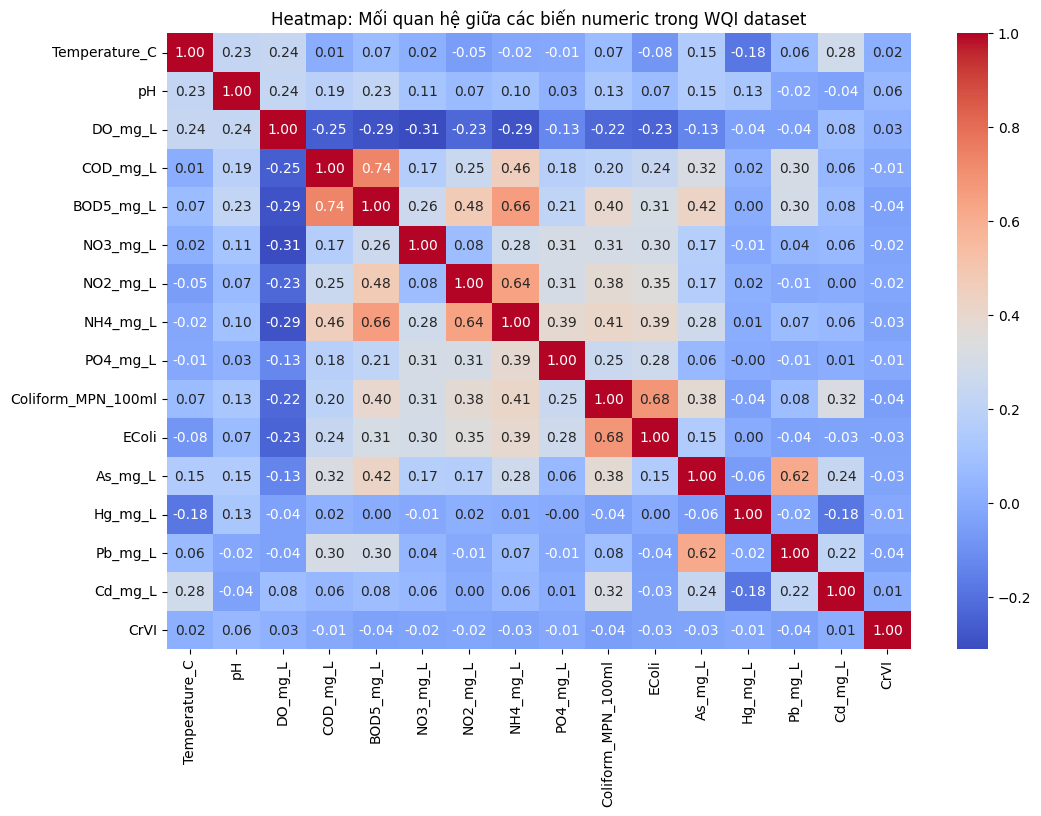

In [ ]:
# Lấy các cột numeric
numeric_cols = wqi_data_convert_cell.select_dtypes(include=['int64', 'float64']).columns
df_numeric = wqi_data_convert_cell[numeric_cols]

# Tính hệ số tương quan (correlation matrix)
corr_matrix = df_numeric.corr()

plt.figure(figsize=(12, 8))  # chỉnh kích thước hình
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Heatmap: Mối quan hệ giữa các biến numeric trong WQI dataset")
plt.show()


In [ ]:

# Danh sách cột numeric cần impute (theo tên mới)
num_cols_to_impute = ['EColi', 'CrVI']

# Các cột còn lại (numeric, không missing)
other_num_cols = [col for col in wqi_data_convert_cell.columns if col not in num_cols_to_impute]

# Tạo bản copy để tránh làm thay đổi gốc
df = wqi_data_convert_cell.copy()

# Chọn các cột để KNN làm việc (có thể dùng toàn bộ dataset để KNN tận dụng thông tin các cột khác)
imputer = KNNImputer(n_neighbors=5)

df[num_cols_to_impute] = imputer.fit_transform(
    df[num_cols_to_impute + other_num_cols]
)[:, :len(num_cols_to_impute)]

wqi_data_convert_cell['EColi'] = df['EColi']
wqi_data_convert_cell['CrVI'] = df['CrVI']

In [ ]:
wqi_data_convert_cell.isnull().sum()

Temperature_C         0
pH                    0
DO_mg_L               0
COD_mg_L              0
BOD5_mg_L             0
NO3_mg_L              0
NO2_mg_L              0
NH4_mg_L              0
PO4_mg_L              0
Coliform_MPN_100ml    0
EColi                 0
As_mg_L               0
Hg_mg_L               0
Pb_mg_L               0
Cd_mg_L               0
CrVI                  0
dtype: int64

## 1.3 Removing Inconsistent values and Outliers (10%)

Detecting inconsistencies can be achieved through a variety of methods. Some can be identified by examining unique values within each column, while others may require a solid understanding of the problem domain. Since you might not be an expert in the hotel or hospitality industry, here are some helpful hints:

Hints:

1. Check for incomplete bookings, such as reservations with zero adults, babies, or children.
2. Examine rows with zeros in both 'stays_in_weekend_nights' and 'stays_in_week_nights.'



C:\Users\Admin\AppData\Local\Temp\ipykernel_1784\4125988468.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=[0]*len(wqi_data_convert_cell), y=wqi_data_convert_cell[col],
C:\Users\Admin\AppData\Local\Temp\ipykernel_1784\4125988468.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=[0]*len(wqi_data_convert_cell), y=wqi_data_convert_cell[col],
C:\Users\Admin\AppData\Local\Temp\ipykernel_1784\4125988468.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=[0]*len(wqi_data_convert_cell), y=wqi_data_convert_cell[col],
C:\Users\Admin\A

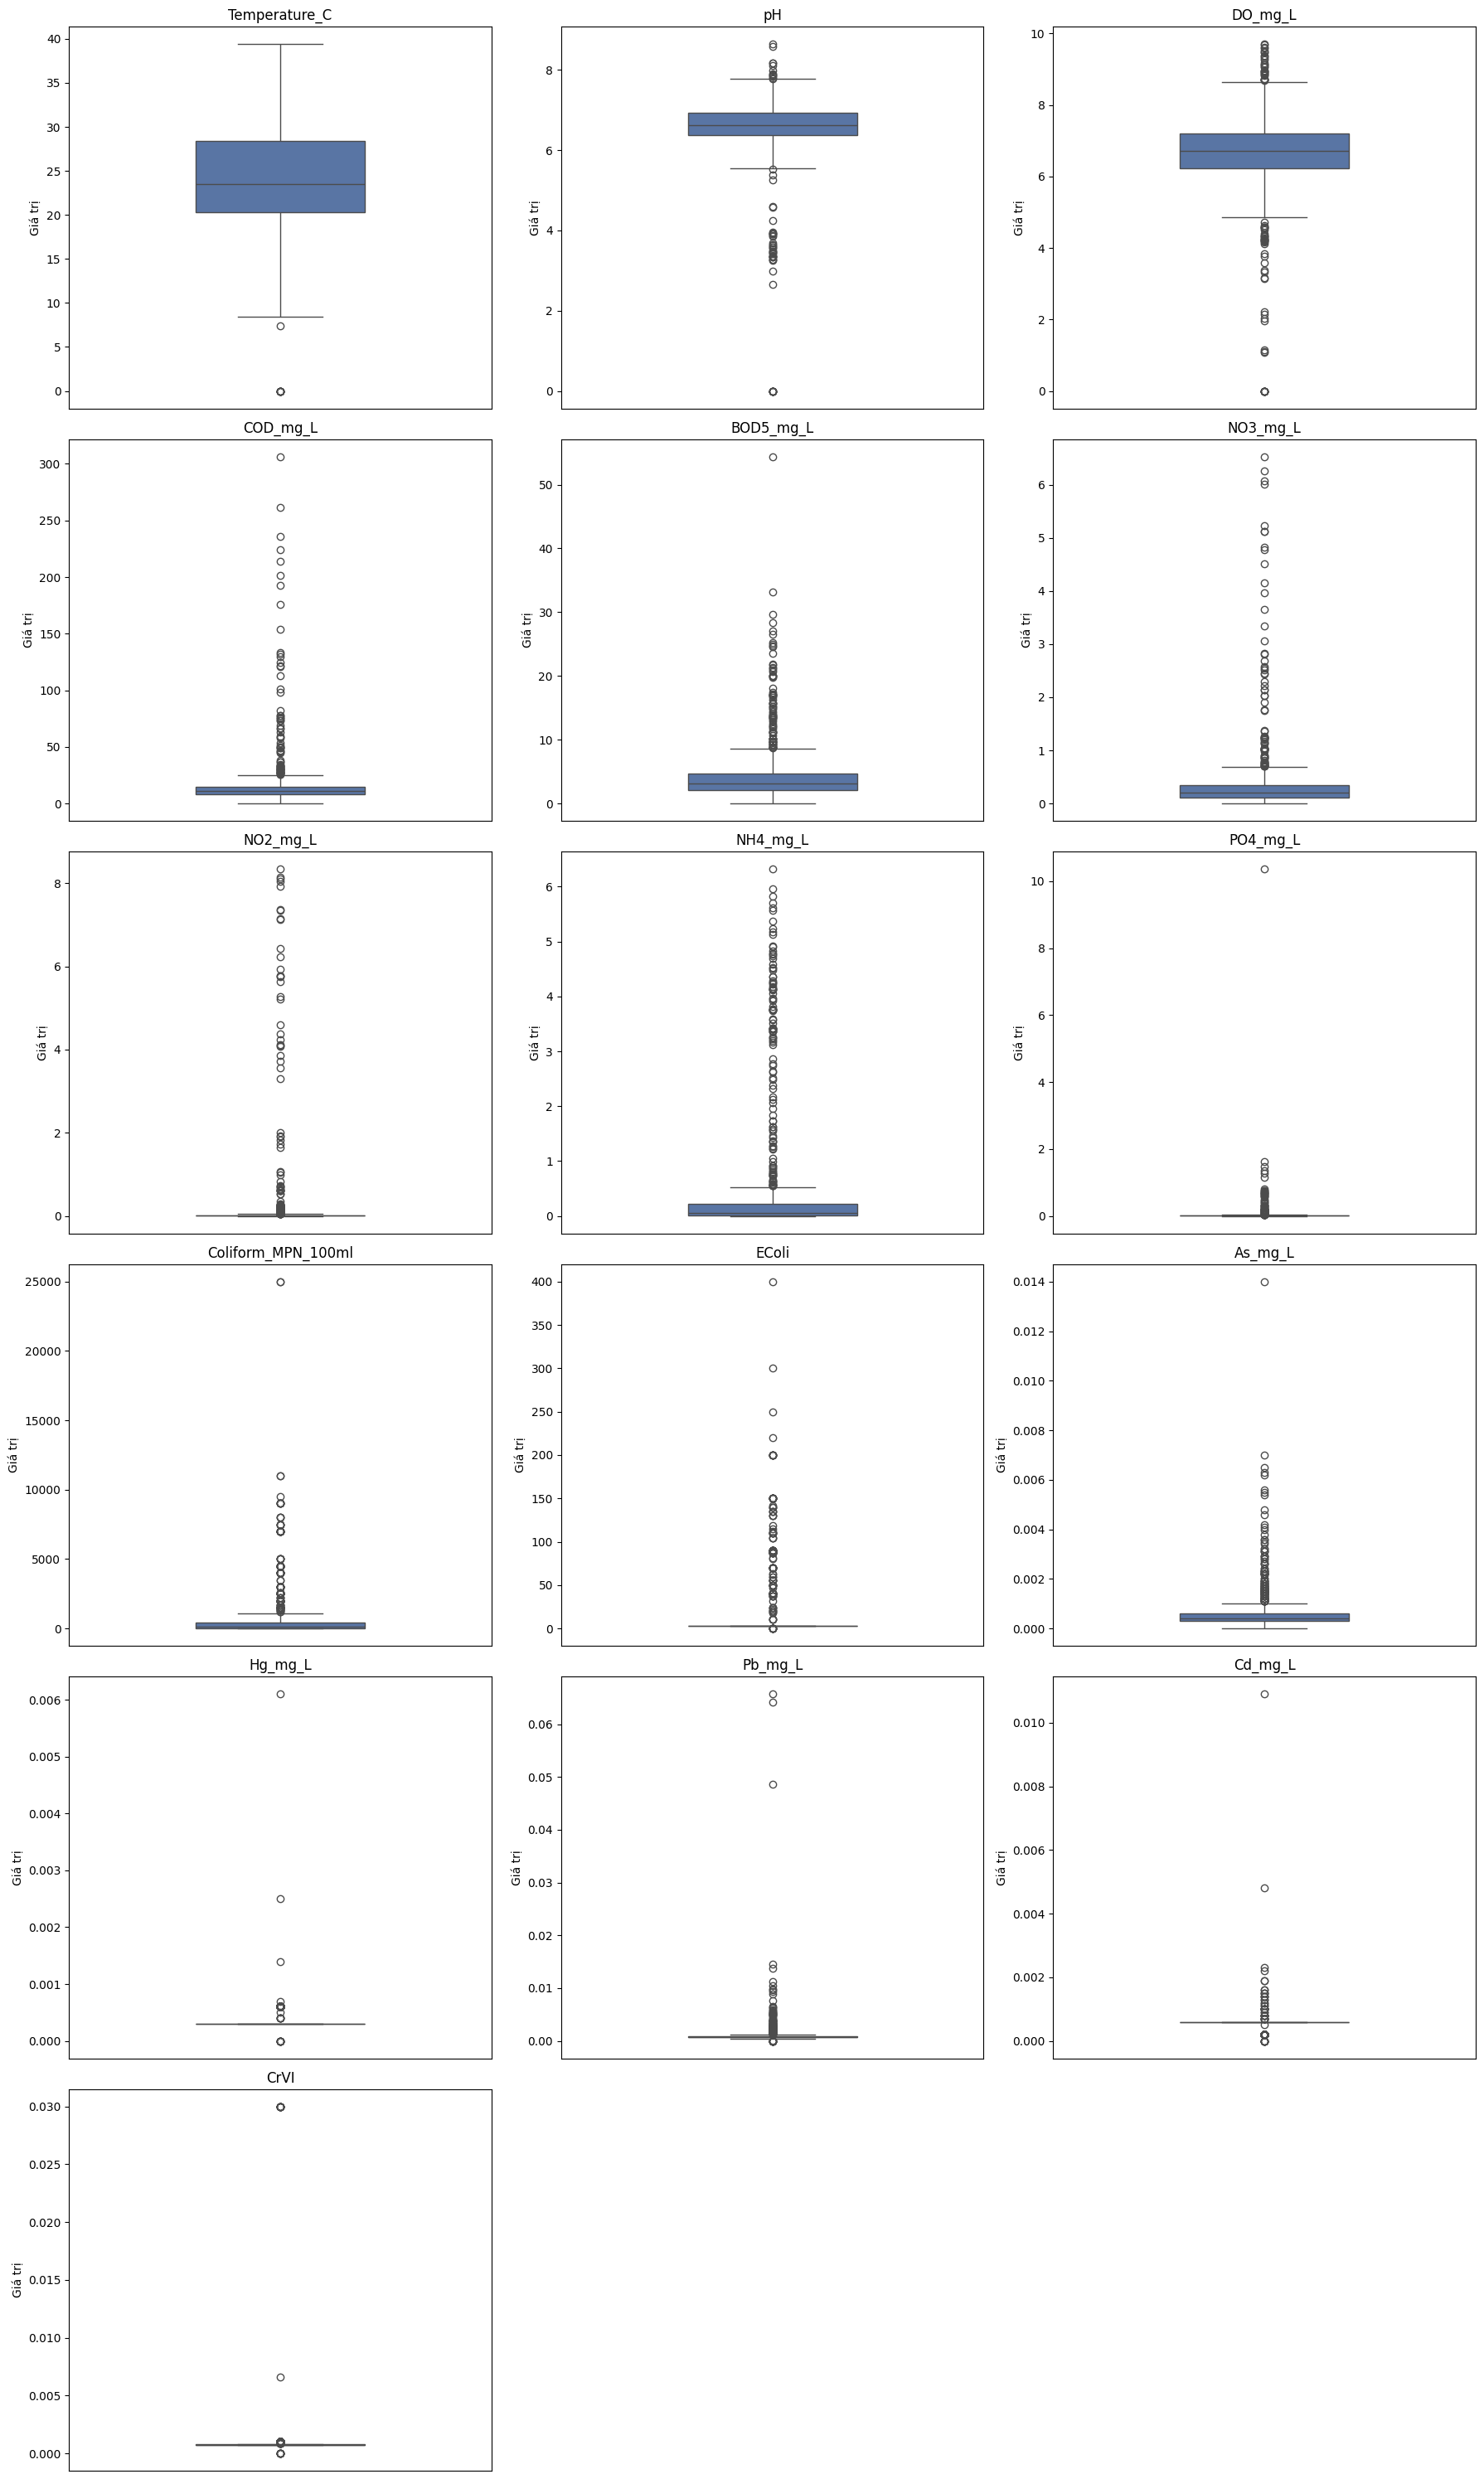

In [ ]:
# Lọc các cột numeric
numeric_cols = wqi_data_convert_cell.select_dtypes(include='number').columns
n_cols = len(numeric_cols)

# Tạo figure với grid
n_rows = (n_cols // 3) + 1
plt.figure(figsize=(18, 5*n_rows))

for i, col in enumerate(numeric_cols):
    ax = plt.subplot(n_rows, 3, i+1)
    # Fix deprecated warning: thêm x tĩnh và legend=False
    sns.boxplot(x=[0]*len(wqi_data_convert_cell), y=wqi_data_convert_cell[col],
                ax=ax, palette=["#4c72b0"], width=0.4, dodge=False)
    ax.set_title(col, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Giá trị")
    ax.set_xticks([])  # ẩn nhãn trục x

plt.tight_layout()
plt.show()

## 1.3 Caculate the WQI output

In [ ]:
# 1. Cấu hình bảng giá trị mốc BP cho từng kim loại (trích xuất từ Bảng 2 trong ảnh)
# Thứ tự các giá trị tương ứng với i = 1, 2, 3, 4, 5
metal_configs = {
    'As_mg_L':   [0.01, 0.02, 0.05, 0.1,  0.1],      # Lưu ý: As mức 5 là >0.1
    'Cd_mg_L':   [0.005, 0.005, 0.008, 0.01, 0.1],
    'Pb_mg_L':   [0.02, 0.02, 0.04, 0.05, 0.5],
    'CrVI': [0.01, 0.02, 0.04, 0.05, 0.1],
    'Cu':   [0.1, 0.2, 0.5, 1.0, 2.0],
    'Zn':   [0.5, 1.0, 1.5, 2.0, 3.0],
    'Hg_mg_L':   [0.001, 0.001, 0.0015, 0.002, 0.01]
}

# Giá trị q tương ứng với các mức i từ 1 đến 5
q_values = [100, 75, 50, 25, 10]

# 2. Hàm tính WQI tổng quát
def calculate_wqi_generic(cp, bp_list):
    if pd.isna(cp) or not isinstance(cp, (int, float)):
        return np.nan

    # Nếu Cp tốt hơn hoặc bằng mức chuẩn cao nhất (mức 1)
    if cp <= bp_list[0]:
        return q_values[0]

    # Nếu Cp tệ hơn hoặc bằng mức thấp nhất (mức 5)
    if cp >= bp_list[4]:
        return q_values[4]

    # Tìm khoảng để áp dụng Công thức 1
    for i in range(len(bp_list) - 1):
        bp_i, bp_i1 = bp_list[i], bp_list[i+1]
        q_i, q_i1 = q_values[i], q_values[i+1]

        if bp_i <= cp <= bp_i1:
            # Trường hợp bp_i == bp_i1 (như Pb, Hg ở mức 1-2)
            if cp == bp_i and i != 0:
                return cp
            if cp == bp_i1 and i != 4:
                return cp

            # Áp dụng Công thức 1
            wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
            return round(wqi, 2)

# 3. Vòng lặp tự động tính cho tất cả các cột có trong cấu hình
for metal, bp_points in metal_configs.items():
    if metal in wqi_data_convert_cell.columns:
        new_col_name = f'WQI_{metal.split()[0]}' # Tạo tên cột như WQI_As, WQI_Cd...
        wqi_data_convert_cell[new_col_name] = wqi_data_convert_cell[metal].apply(
            lambda x: calculate_wqi_generic(x, bp_points)
        )

# Hiển thị kết quả kiểm tra 5 dòng đầu
print(wqi_data_convert_cell.head())

   Temperature_C    pH  DO_mg_L  COD_mg_L  BOD5_mg_L  NO3_mg_L  NO2_mg_L  \
0           21.5  7.90     8.23       9.8        4.5     0.747     0.064   
1           24.1  7.29     7.28      10.2        4.7     0.434     0.060   
2           28.4  6.81     7.18      19.2        7.2     0.492     0.002   
3           26.7  7.42     6.25      15.2        5.4     0.266     0.002   
4           17.1  6.31     7.44       5.3        1.8     0.865     0.023   

   NH4_mg_L  PO4_mg_L  Coliform_MPN_100ml  ...  As_mg_L  Hg_mg_L  Pb_mg_L  \
0     0.154     0.024               400.0  ...   0.0004   0.0003   0.0007   
1     0.215     0.010              2000.0  ...   0.0005   0.0003   0.0007   
2     0.232     0.057              4500.0  ...   0.0004   0.0003   0.0018   
3     0.522     0.098              7000.0  ...   0.0006   0.0003   0.0011   
4     0.096     0.048                40.0  ...   0.0003   0.0003   0.0001   

   Cd_mg_L     CrVI  WQI_As_mg_L  WQI_Cd_mg_L  WQI_Pb_mg_L  WQI_CrVI  \
0   0.00

In [ ]:
def calculate_wqi_do(do_measured, temp):
    """
    Tính WQI cho thông số DO dựa trên nhiệt độ và nồng độ DO hòa tan.
    do_measured: Cột 'DO mg/l'
    temp: Cột 'Nhiệt độ (0C)'
    """
    if pd.isna(do_measured) or pd.isna(temp) or not isinstance(do_measured, (int, float)) or not isinstance(temp, (int, float)):
        return np.nan

    # Bước 1: Tính DO bão hòa (DO_baohua) dựa trên nhiệt độ T
    # Công thức: 14.652 - 0.41022*T + 0.0079910*T^2 - 0.0000777747*T^3
    do_sat = (14.652 - 0.41022 * temp +
              0.0079910 * (temp**2) -
              0.000077774 * (temp**3))

    # Tính giá trị DO % bão hòa (Cp)
    cp = (do_measured / do_sat) * 100

    # Bảng 3: Quy định giá trị BPi và qi đối với DO % bão hòa
    bp_do = [20, 50, 75, 88, 112, 125, 150, 200]
    q_do = [25, 50, 75, 100, 100, 75, 50, 25]

    # Kiểm tra nếu Cp trùng đúng với các giá trị mốc trong bảng
    for i, bp_val in enumerate(bp_do):
        if round(cp, 2) == bp_val:
            return q_do[i]

    # Các điều kiện đặc biệt theo hướng dẫn
    if cp < 20 or cp > 200:
        return 10

    if 88 <= cp <= 112:
        return 100

    # Trường hợp 20 < Cp < 88: Sử dụng Công thức 2
    if 20 < cp < 88:
        # Xác định khoảng i
        for i in range(0, 3): # Chỉ xét các mốc 20, 50, 75, 88
            bp_i, bp_i1 = bp_do[i], bp_do[i+1]
            q_i, q_i1 = q_do[i], q_do[i+1]

            if bp_i < cp < bp_i1:
                # Công thức 2: WQI = [(qi+1 - qi) / (BPi+1 - BPi)] * (Cp - BPi) + qi
                wqi = ((q_i1 - q_i) / (bp_i1 - bp_i)) * (cp - bp_i) + q_i
                return round(wqi, 2)

    # Trường hợp 112 < Cp < 200: Sử dụng Công thức 1
    if 112 < cp < 200:
        # Xác định khoảng i (các mốc 112, 125, 150, 200)
        for i in range(4, 7):
            bp_i, bp_i1 = bp_do[i], bp_do[i+1]
            q_i, q_i1 = q_do[i], q_do[i+1]

            if bp_i < cp < bp_i1:
                # Công thức 1: WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
                wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
                return round(wqi, 2)


# Áp dụng cho DataFrame
# Lưu ý: Thay đổi tên cột 'Nhiệt độ (0C)' nếu trong file của bạn đặt tên khác
wqi_data_convert_cell['WQI_DO'] = wqi_data_convert_cell.apply(
    lambda row: calculate_wqi_do(row['DO_mg_L'], row['Temperature_C']), axis=1
)

print(wqi_data_convert_cell[['DO_mg_L', 'Temperature_C', 'WQI_DO']].head())

   DO_mg_L  Temperature_C  WQI_DO
0     8.23           21.5  100.00
1     7.28           24.1   99.07
2     7.18           28.4  100.00
3     6.25           26.7   82.61
4     7.44           17.1   80.04


In [ ]:
def calculate_wqi_ph(cp):
    """
    Tính WQI cho thông số pH dựa trên Bảng 4 và các công thức nội suy.
    cp: giá trị pH quan trắc được.
    """
    if pd.isna(cp) or not isinstance(cp, (int, float)):
        return np.nan

    # Bảng 4: Quy định giá trị BPi và qi đối với pH
    # i=1: <5.5 (q=10), i=2: 5.5 (q=50), i=3: 6 (q=100)
    # i=4: 8.5 (q=100), i=5: 9 (q=50), i=6: >9 (q=10)

    # 1. Trường hợp nằm ngoài khoảng hoặc trùng mốc biên cực đoan
    if cp < 5.5 or cp > 9:
        return 10


    # 2. Trường hợp trùng khớp với các giá trị mốc BP trong bảng
    if cp == 5.5: return 50
    if cp == 6.0: return 100
    if cp == 8.5: return 100
    if cp == 9.0: return 50

    # 3. Trường hợp 5.5 < pH < 6: Sử dụng Công thức 2
    if 5.5 < cp < 6:
        # i=2 (BPi=5.5, qi=50); i+1=3 (BPi+1=6, qi+1=100)
        bp_i, bp_i1 = 5.5, 6.0
        q_i, q_i1 = 50, 100
        # WQI = [(qi+1 - qi) / (BPi+1 - BPi)] * (Cp - BPi) + qi
        wqi = ((q_i1 - q_i) / (bp_i1 - bp_i)) * (cp - bp_i) + q_i
        return round(wqi, 2)

    # 4. Trường hợp 6 <= pH <= 8.5: WQI = 100
    if 6 <= cp <= 8.5:
        return 100

    # 5. Trường hợp 8.5 < pH < 9: Sử dụng Công thức 1
    if 8.5 < cp < 9:
        # i=4 (BPi=8.5, qi=100); i+1=5 (BPi+1=9, qi+1=50)
        bp_i, bp_i1 = 8.5, 9.0
        q_i, q_i1 = 100, 50
        # WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
        wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
        return round(wqi, 2)

# Áp dụng cho toàn bộ dữ liệu trong cột 'pH'
wqi_data_convert_cell['WQI_ph'] = wqi_data_convert_cell['pH'].apply(calculate_wqi_ph)

# Hiển thị kết quả kiểm tra
print(wqi_data_convert_cell[['pH', 'WQI_ph']].head())

     pH  WQI_ph
0  7.90   100.0
1  7.29   100.0
2  6.81   100.0
3  7.42   100.0
4  6.31   100.0


In [ ]:
# 1. Cấu hình bảng giá trị mốc BP cho từng thông số (theo Bảng 1 trong ảnh)
# Thứ tự q tương ứng: 100, 75, 50, 25, 10
q_values = [100, 75, 50, 25, 10]

params_config = {
    'BOD5_mg_L':          [4, 6, 15, 25, 50],
    'COD_mg_L':           [10, 15, 30, 50, 150],
    #'TOC':                [4, 6, 15, 25, 50],
    'NH4_mg_L':          [0.3, 0.3, 0.6, 0.9, 5],   # BP1=0.3 (L1 là <0.3)
    'NO3_mg_L':           [2, 5, 10, 15, 15],        # L5 là >15
    'PO4_mg_L':         [0.1, 0.2, 0.3, 0.5, 4],
    'Coliform_MPN_100ml': [2500, 5000, 7500, 10000, 10000], # L5 là >10000
    'EColi':             [20, 50, 100, 200, 200]    # L5 là >200
}

# 2. Hàm tính WQI SI tổng quát (Áp dụng Công thức 1)
def calculate_wqi_formula1(cp, bp_list):
    if pd.isna(cp): return np.nan

    # Trường hợp trùng với mốc biên hoặc vượt ngưỡng cực đoan
    if cp <= bp_list[0]: return q_values[0]
    if cp >= bp_list[4]: return q_values[4]

    # Kiểm tra nếu giá trị Cp trùng đúng với điểm mốc BPi
    for i, bp_val in enumerate(bp_list):
        if cp == bp_val:
            return q_values[i]

    # Áp dụng Công thức 1 cho các khoảng giữa
    for i in range(len(bp_list) - 1):
        bp_i, bp_i1 = bp_list[i], bp_list[i+1]
        q_i, q_i1 = q_values[i], q_values[i+1]

        if bp_i < cp < bp_i1:
            # WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
            wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
            return round(wqi, 2)

# 3. Vòng lặp tự động tính cho các cột (Trừ NO2- xử lý riêng)
for param, bp_points in params_config.items():
    if param in wqi_data_convert_cell.columns:
        # Tạo tên cột mới, ví dụ: WQI_BOD5, WQI_NH4...
        new_col = f"WQI_{param.replace('+', '').replace('-', '')}"
        wqi_data_convert_cell[new_col] = wqi_data_convert_cell[param].apply(
            lambda x: calculate_wqi_formula1(x, bp_points)
        )

# 4. Xử lý riêng cho NO2- (Vì bảng chỉ có 2 mức: <=0.05 và >0.05)
if 'NO2_mg_L' in wqi_data_convert_cell.columns:
    wqi_data_convert_cell['WQI_NO2_mg_L'] = wqi_data_convert_cell['NO2_mg_L'].apply(
        lambda x: 100 if x <= 0.05 else 10 if x > 0.05 else np.nan
    )

# Hiển thị kết quả các cột WQI vừa tạo
wqi_cols = [c for c in wqi_data_convert_cell.columns if c.startswith('WQI_')]
print(wqi_data_convert_cell[wqi_cols].head())

   WQI_As_mg_L  WQI_Cd_mg_L  WQI_Pb_mg_L  WQI_CrVI  WQI_Hg_mg_L  WQI_DO  \
0        100.0        100.0        100.0     100.0        100.0  100.00   
1        100.0        100.0        100.0     100.0        100.0   99.07   
2        100.0        100.0        100.0     100.0        100.0  100.00   
3        100.0        100.0        100.0     100.0        100.0   82.61   
4        100.0        100.0        100.0     100.0        100.0   80.04   

   WQI_ph  WQI_BOD5_mg_L  WQI_COD_mg_L  WQI_NH4_mg_L  WQI_NO3_mg_L  \
0   100.0          93.75        100.00         100.0         100.0   
1   100.0          91.25         99.00         100.0         100.0   
2   100.0          71.67         68.00         100.0         100.0   
3   100.0          82.50         74.67          56.5         100.0   
4   100.0         100.00        100.00         100.0         100.0   

   WQI_PO4_mg_L  WQI_Coliform_MPN_100ml  WQI_EColi  WQI_NO2_mg_L  
0         100.0                   100.0     100.00           

In [ ]:
wqi_data_convert_cell.isnull().sum()

Temperature_C             0
pH                        0
DO_mg_L                   0
COD_mg_L                  0
BOD5_mg_L                 0
NO3_mg_L                  0
NO2_mg_L                  0
NH4_mg_L                  0
PO4_mg_L                  0
Coliform_MPN_100ml        0
EColi                     0
As_mg_L                   0
Hg_mg_L                   0
Pb_mg_L                   0
Cd_mg_L                   0
CrVI                      0
WQI_As_mg_L               0
WQI_Cd_mg_L               0
WQI_Pb_mg_L               0
WQI_CrVI                  0
WQI_Hg_mg_L               0
WQI_DO                    0
WQI_ph                    0
WQI_BOD5_mg_L             0
WQI_COD_mg_L              0
WQI_NH4_mg_L              0
WQI_NO3_mg_L              0
WQI_PO4_mg_L              0
WQI_Coliform_MPN_100ml    0
WQI_EColi                 0
WQI_NO2_mg_L              0
dtype: int64

In [ ]:
def calculate_final_vn_wqi(row):
    # 1. Phân nhóm các thông số (Dựa trên image_8a4caa.png)
    group_i_cols = ['WQI_ph']

    # Nhóm II: Thuốc bảo vệ thực vật (Nếu bạn có dữ liệu này)
    group_ii_cols = [col for col in row.index if col.startswith('WQI_') and
                     any(p in col for p in ['Aldrin', 'DDTs', 'BHC', 'Dieldrin'])]

    # Nhóm III: Kim loại nặng
    group_iii_cols = ['WQI_As_mg_L', 'WQI_Cd_mg_L', 'WQI_Pb_mg_L', 'WQI_CrVI', 'WQI_Cu', 'WQI_Zn', 'WQI_Hg_mg_L']

    # Nhóm IV: Hữu cơ & Dinh dưỡng (Bắt buộc - ít nhất 3 thông số)
    group_iv_cols = ['WQI_DO', 'WQI_BOD5_mg_L', 'WQI_COD_mg_L', 'WQI_TOC', 'NH4_mg_L', 'NO3_mg_L', 'WQI_NO2_mg_L', 'WQI_PO4_mg_L']

    # Nhóm V: Vi sinh
    group_v_cols = ['WQI_Coliform_MPN_100ml', 'WQI_EColi']

    # 2. Kiểm tra điều kiện tính toán
    # - Bắt buộc có nhóm IV và nhóm IV phải có ít nhất 3 thông số
    valid_iv = [row[c] for c in group_iv_cols if c in row.index and pd.notna(row[c])]
    if len(valid_iv) < 3:
        return np.nan # Không đủ điều kiện tính VN_WQI

    # - Phải có tối thiểu 3/5 nhóm thông số
    available_groups = 0
    groups_data = {}

    for g_name, cols in [('I', group_i_cols), ('II', group_ii_cols),
                         ('III', group_iii_cols), ('IV', group_iv_cols), ('V', group_v_cols)]:
        valid_vals = [row[c] for c in cols if c in row.index and pd.notna(row[c])]
        if valid_vals:
            available_groups += 1
            groups_data[g_name] = valid_vals

    if available_groups < 3:
        return np.nan

    # 3. Tính toán giá trị trung bình cho từng nhóm
    # Nhóm I: WQI_I
    wqi_1 = groups_data['I'][0] if 'I' in groups_data else 100

    # Nhóm II & III: Trung bình nhân (Geometric Mean)
    wqi_2_val = gmean(groups_data['II']) if 'II' in groups_data else 100
    wqi_3_val = gmean(groups_data['III']) if 'III' in groups_data else 100

    # Nhóm IV & V: Trung bình cộng (Arithmetic Mean)
    wqi_4_avg = np.mean(groups_data['IV'])
    wqi_5_avg = np.mean(groups_data['V']) if 'V' in groups_data else np.nan

    # 4. Áp dụng Công thức 3
    # Thành phần căn bậc hai của nhóm IV và V
    if not np.isnan(wqi_5_avg):
        bracket_term = np.sqrt(wqi_4_avg * wqi_5_avg)
    else:
        bracket_term = wqi_4_avg # Nếu thiếu nhóm V, chỉ dùng nhóm IV

    final_wqi = (wqi_1 / 100) * (wqi_2_val / 100) * (wqi_3_val / 100) * bracket_term

    return round(final_wqi, 0)

# Áp dụng tính toán cho toàn bộ DataFrame
wqi_data_convert_cell['VN_WQI'] = wqi_data_convert_cell.apply(calculate_final_vn_wqi, axis=1)

# Hiển thị kết quả cuối cùng
print(wqi_data_convert_cell[['VN_WQI']].head())

   VN_WQI
0    76.0
1    71.0
2    69.0
3    56.0
4    83.0


In [ ]:
wqi_data_convert_cell.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1110 entries, 0 to 1109
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature_C           1110 non-null   float64
 1   pH                      1110 non-null   float64
 2   DO_mg_L                 1110 non-null   float64
 3   COD_mg_L                1110 non-null   float64
 4   BOD5_mg_L               1110 non-null   float64
 5   NO3_mg_L                1110 non-null   float64
 6   NO2_mg_L                1110 non-null   float64
 7   NH4_mg_L                1110 non-null   float64
 8   PO4_mg_L                1110 non-null   float64
 9   Coliform_MPN_100ml      1110 non-null   float64
 10  EColi                   1110 non-null   float64
 11  As_mg_L                 1110 non-null   float64
 12  Hg_mg_L                 1110 non-null   float64
 13  Pb_mg_L                 1110 non-null   float64
 14  Cd_mg_L                 1110 non-null   

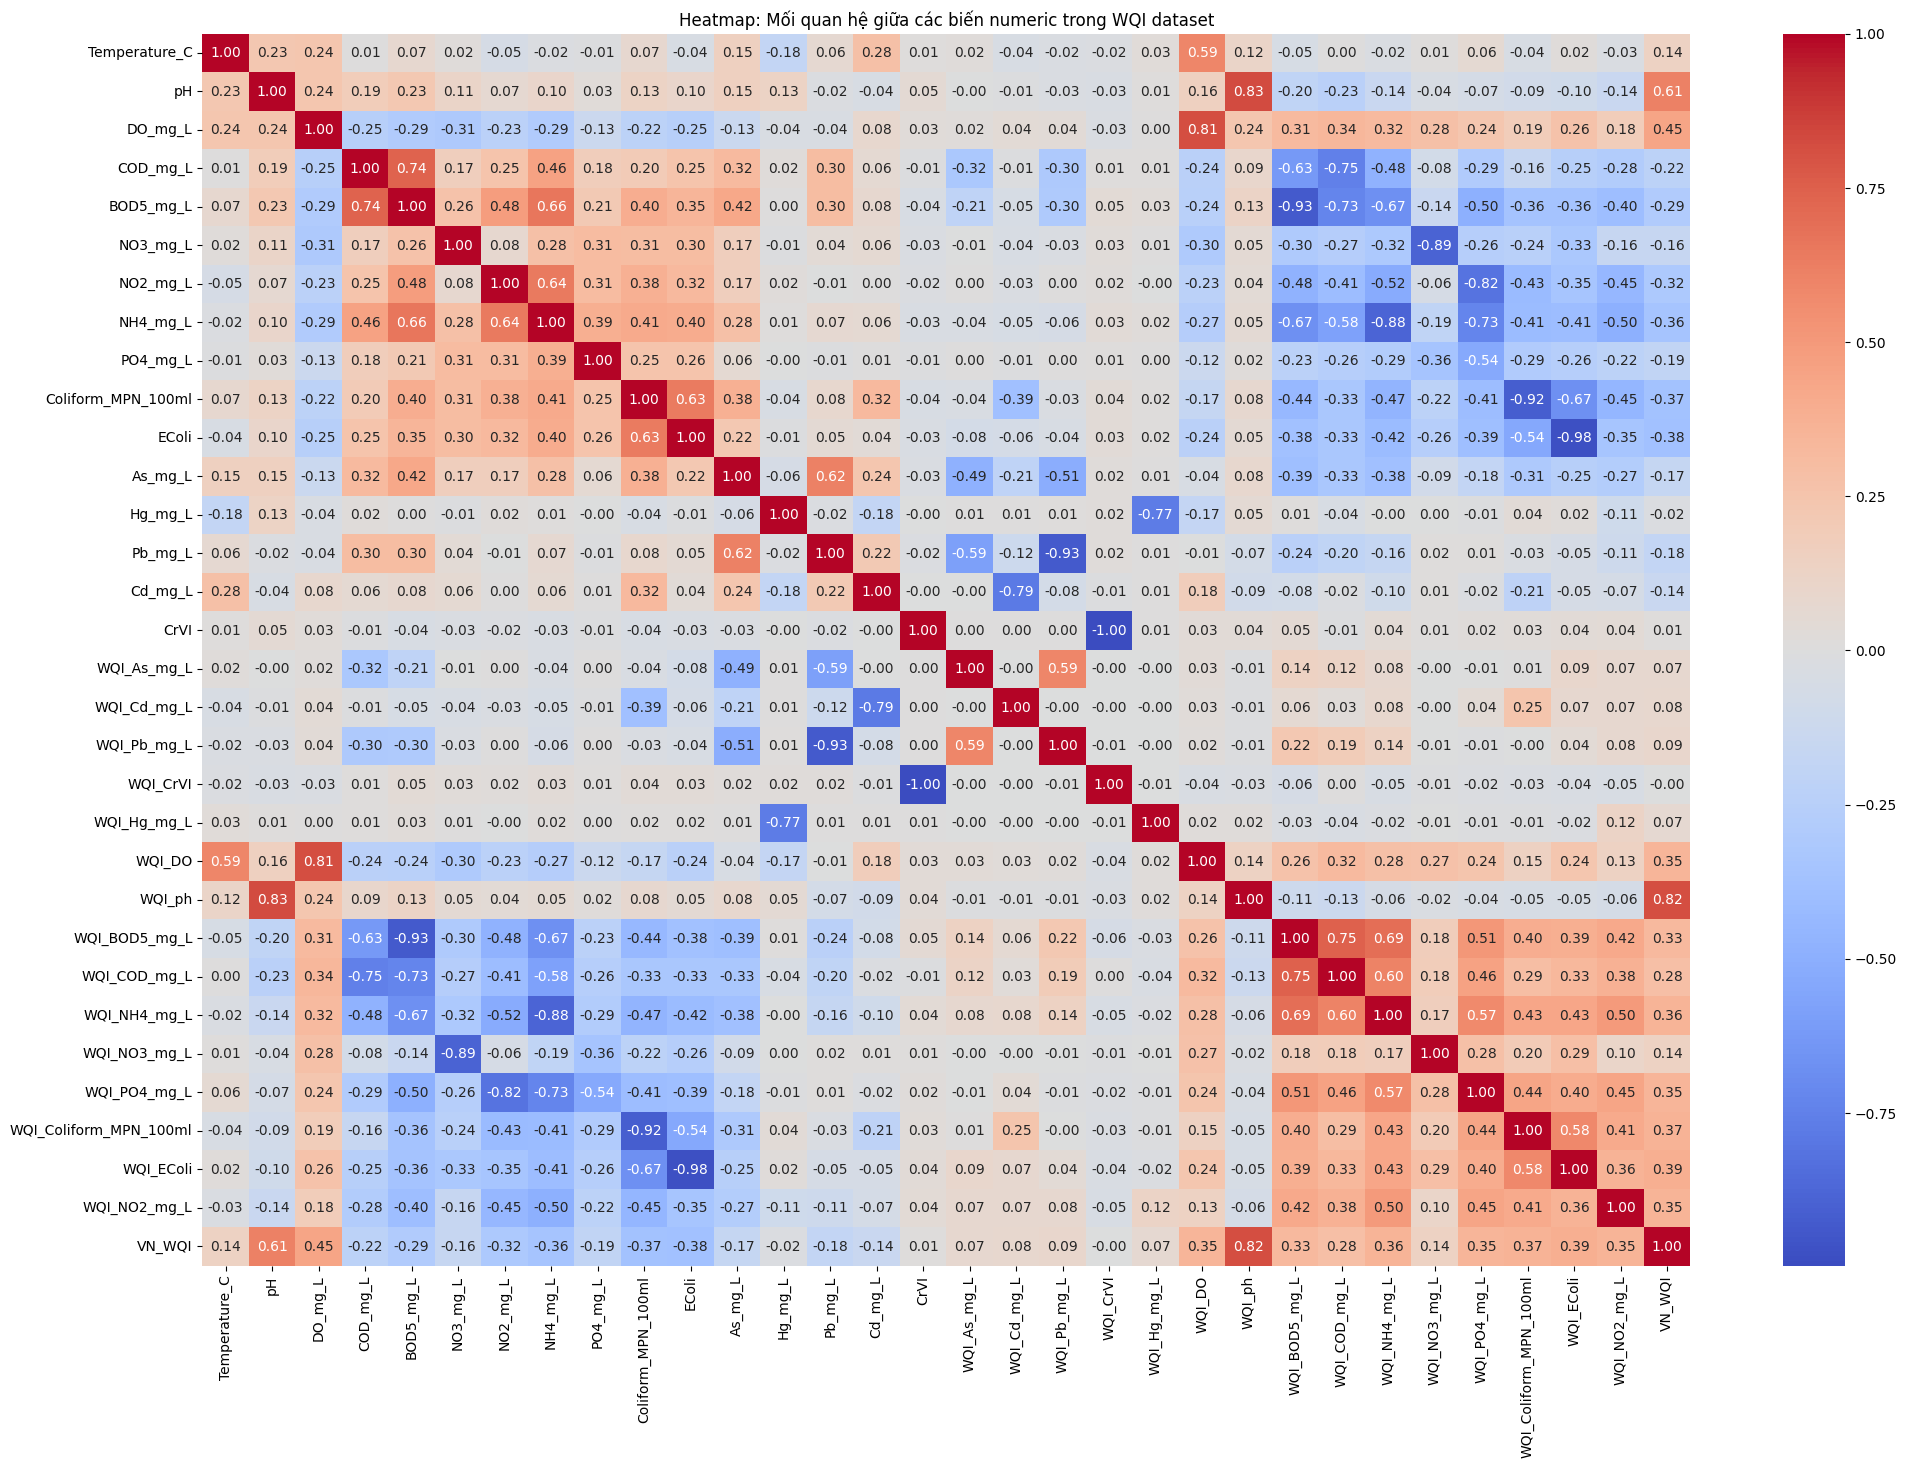

In [ ]:
# Lấy các cột numeric
numeric_cols = wqi_data_convert_cell.select_dtypes(include=['int64', 'float64']).columns
df_numeric = wqi_data_convert_cell[numeric_cols]

# Tính hệ số tương quan (correlation matrix)
corr_matrix = df_numeric.corr()

plt.figure(figsize=(24, 16))  # chỉnh kích thước hình
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Heatmap: Mối quan hệ giữa các biến numeric trong WQI dataset")
plt.show()


In [ ]:
final_data = wqi_data_convert_cell.drop(columns=['WQI_As_mg_L', 'WQI_Cd_mg_L', 'WQI_Pb_mg_L', 'WQI_CrVI', 'WQI_Hg_mg_L', 'WQI_DO', 'WQI_ph', 'WQI_BOD5_mg_L', 'WQI_COD_mg_L', 'WQI_NH4_mg_L', 'WQI_NO3_mg_L', 'WQI_PO4_mg_L', 'WQI_Coliform_MPN_100ml', 'WQI_EColi', 'WQI_NO2_mg_L'])

# 2. Exploratory Data Analysis (25%)


---





You've also been provided with examples of valuable insights that could be of interest to hotel management, including:

* Calculating cancellation percentages for City and Resort hotels.
* Identifying the most frequently ordered meal types.
* Determining the number of returning guests.
* Discovering the most booked room types.
* Exploring correlations between room types and cancellations.


For each of these tasks, choose a suitable type of visualisation covered in
the practical sessions, such as:

* Bar graphs
* Pie charts
* Line charts
* Heatmaps

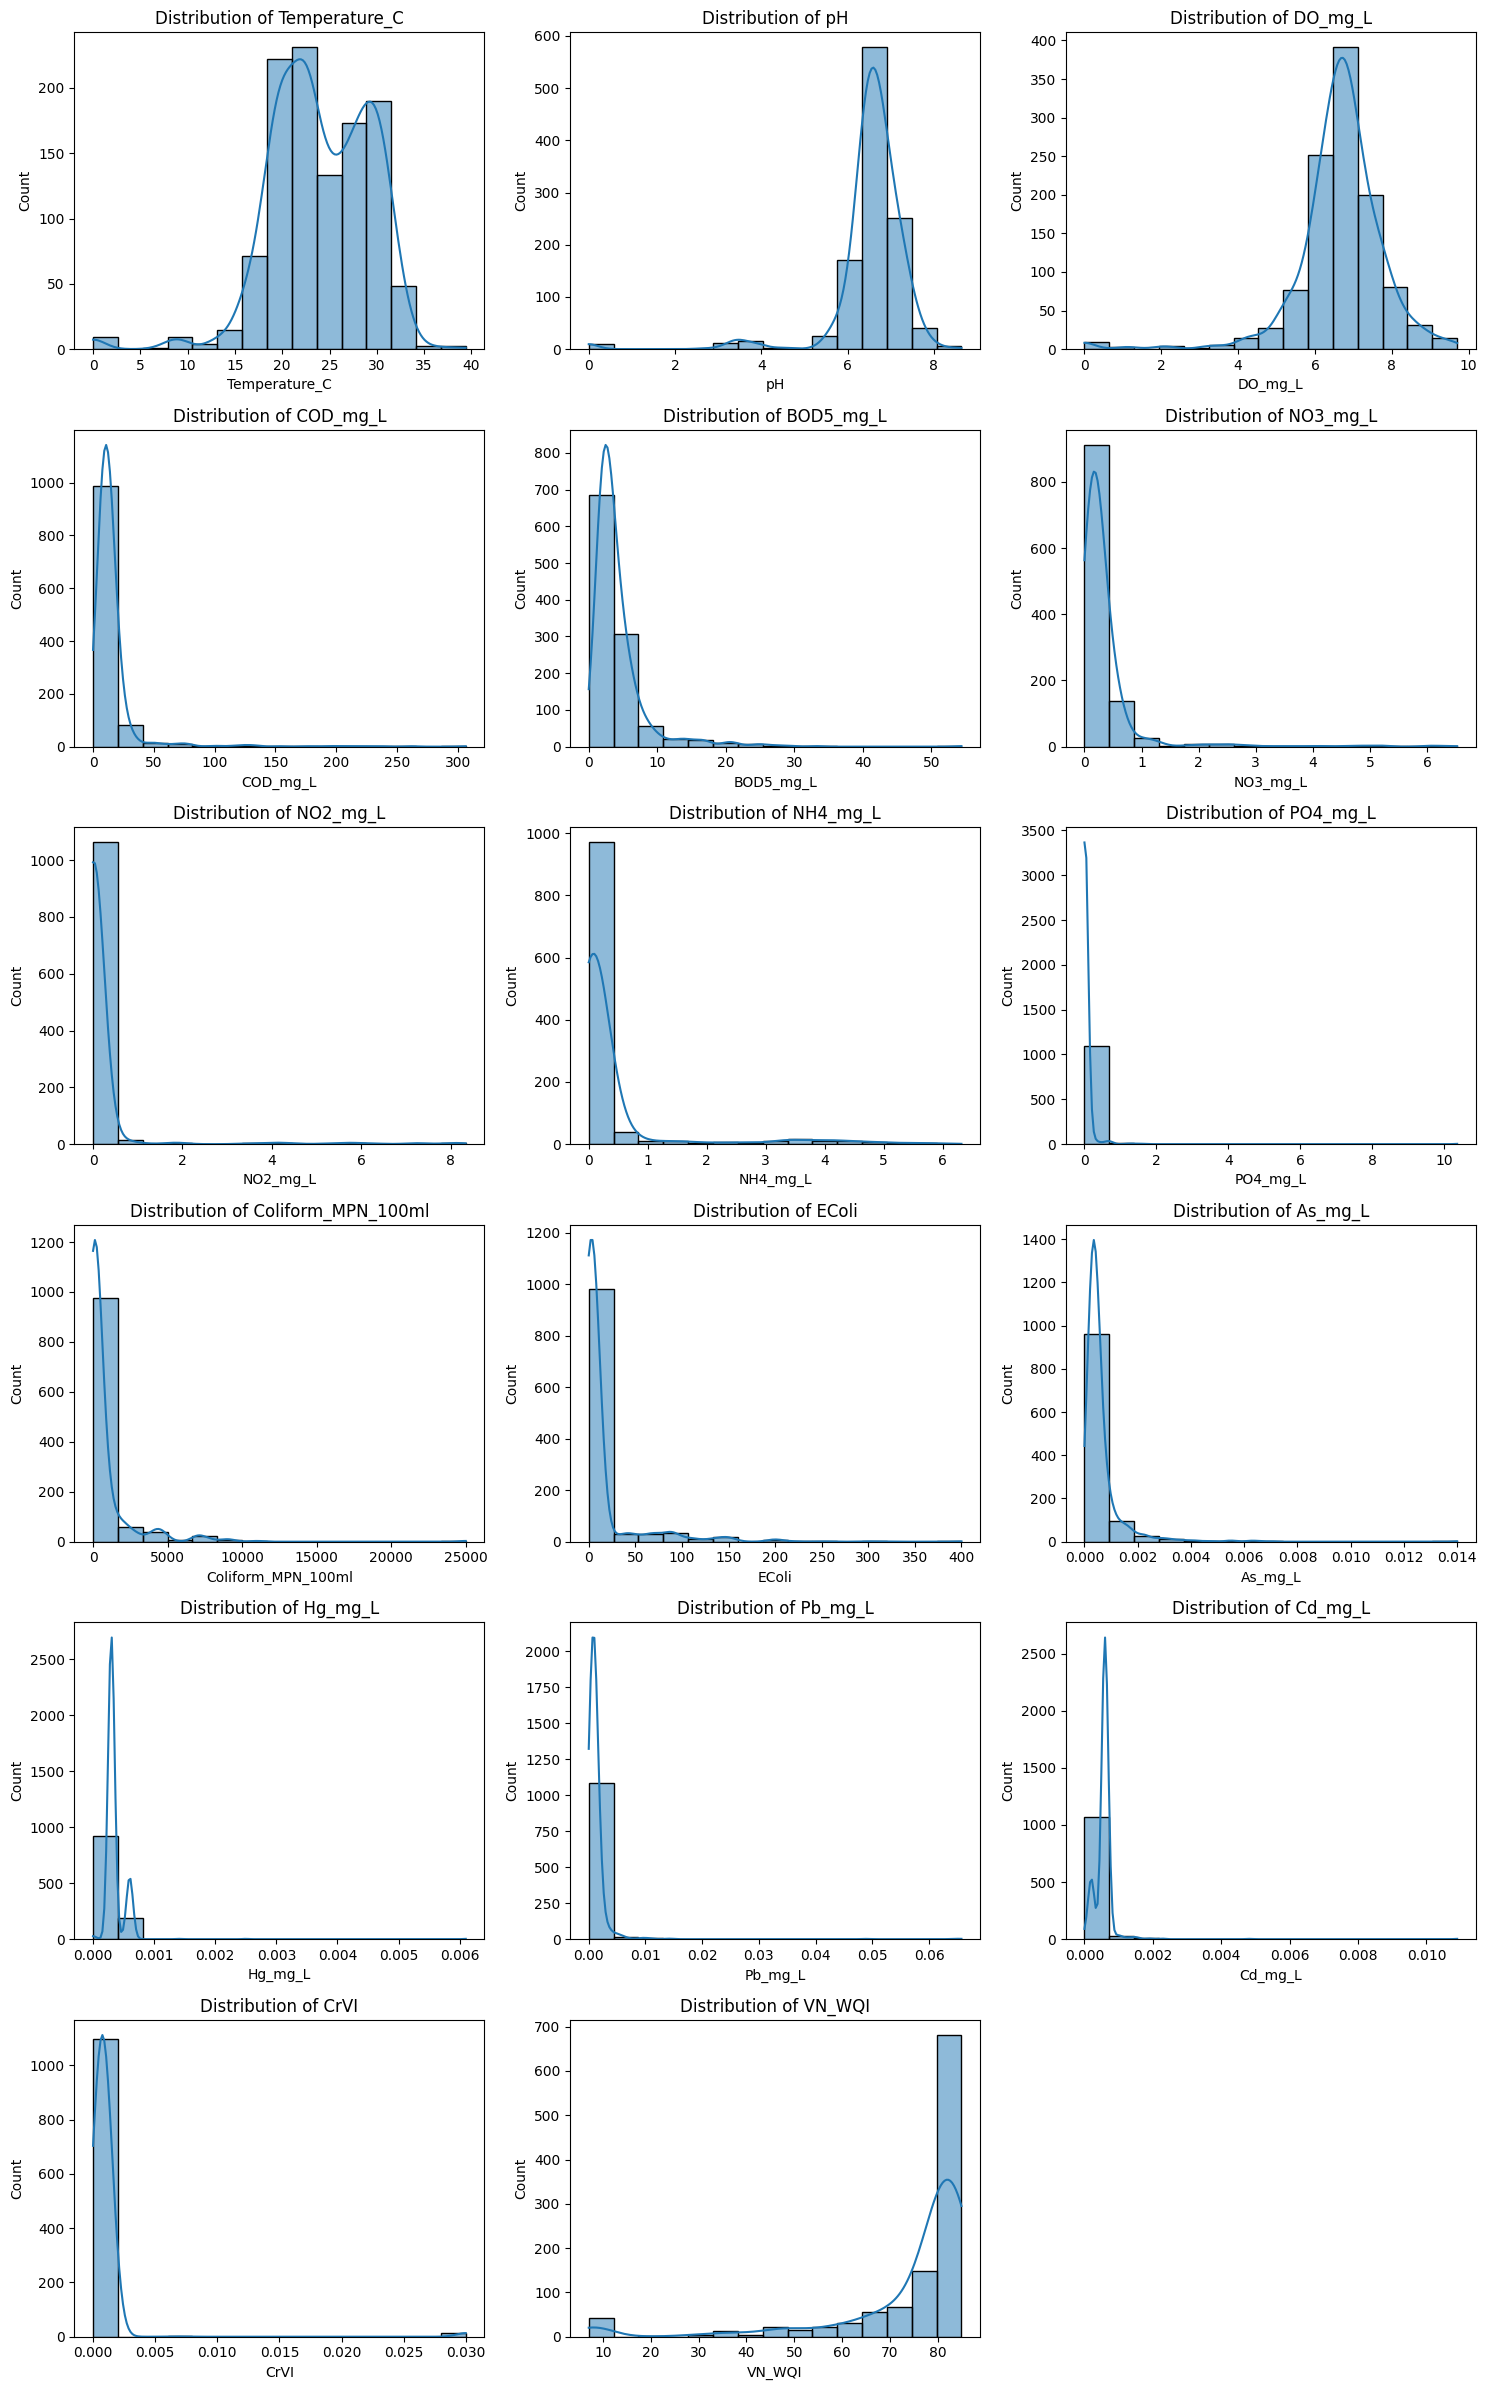

In [ ]:
numeric_cols = final_data.select_dtypes(include=['int64', 'float64']).columns

# Số lượng subplot
n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

plt.figure(figsize=(5 * n_cols, 4 * n_rows))

for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.histplot(final_data[col], bins=15, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

# 3. Feature Engineering (20%)


---





Apply various feature engineering techniques, covered in the lectures and practicals.

Hint:
* Binning
* Encoding
* Scaling
* Feature selection

In [ ]:
class LRWrapper(LinReg := LinearRegression):
    def __init__(self, degree=2, **kwargs):
        super().__init__(**kwargs)
        self.degree = degree

    def fit(self, X, y):
        # tạo scaler và poly
        self.scaler_ = StandardScaler()
        self.poly_ = PolynomialFeatures(degree=self.degree, interaction_only=True, include_bias=False)

        # scale và transform
        X_scaled = self.scaler_.fit_transform(X)
        X_poly = self.poly_.fit_transform(X_scaled)

        # gọi fit của LinearRegression
        super().fit(X_poly, y)
        return self

    def predict(self, X):
        X_scaled = self.scaler_.transform(X)
        X_poly = self.poly_.transform(X_scaled)
        return super().predict(X_poly)

# 4. Classifier Training (20%)


---


Utilise the sklearn Python library to train a ML model (e.g.decision tree classifier). Your process should start with splitting your dataset into input features (X) and a target feature (y). Next, divide the data into 70% training and 30% testing subsets. Train your model on the training dataset and evaluate using test dataset with appropriate metrics. Aim to achieve higher accuracy e.g. more than 70% accuracy using your model.

## 4.1. Data Splitting (5%)

In [ ]:
final_data.shape

(1110, 17)

In [ ]:
# Separate X and y
X = final_data[['Temperature_C', 'pH', 'DO_mg_L', 'COD_mg_L', 'BOD5_mg_L', 
                'NO3_mg_L', 'NO2_mg_L', 'NH4_mg_L', 'PO4_mg_L', 
                'Coliform_MPN_100ml', 'EColi', 'As_mg_L', 'Hg_mg_L', 'Pb_mg_L', 
                'Cd_mg_L', 'CrVI']]  # Features
y = final_data['VN_WQI']  # WQI index

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Reset index
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

# Combine
train_df = pd.concat([X_train, y_train], axis=1)

# Apply SMOGN
data_smogn = smogn.smoter(data=train_df, y='VN_WQI')
X_train_smogn = data_smogn.drop(columns=['VN_WQI'])
y_train_smogn = data_smogn['VN_WQI']

r_index: 100%|########################################################################| 87/87 [00:00<00:00, 831.23it/s]


## 4.2. Model Training (10%)

In [ ]:
# Define the parameter grid for RandomForest
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30],
    'min_samples_split': [5, 10, 15]
}

# Initialize GridSearchCV for RandomForest
rf_grid_search = GridSearchCV(RandomForestRegressor(random_state=42), rf_param_grid, cv=5, n_jobs=-1)
rf_grid_search.fit(X_train_smogn, y_train_smogn)

# Get the best hyperparameters from GridSearchCV
best_rf_params = rf_grid_search.best_params_
print("Best parameters for RandomForest:", best_rf_params)

Best parameters for RandomForest: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}


In [ ]:
# Define the parameter grid for GradientBoosting
gb_param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

# Initialize GridSearchCV for GradientBoosting
gb_grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_param_grid, cv=5, n_jobs=-1)
gb_grid_search.fit(X_train_smogn, y_train_smogn)

# Get the best hyperparameters from GridSearchCV
best_gb_params = gb_grid_search.best_params_
print("Best parameters for GradientBoosting:", best_gb_params)

Best parameters for GradientBoosting: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}


In [ ]:
# Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_smogn, y_train_smogn)
rf_pred = rf_model.predict(X_test)

# Linear Regression model
lr_model = LRWrapper()
lr_model.fit(X_train_smogn, y_train_smogn)
lr_pred = lr_model.predict(X_test)

# Gradient Boosting model
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_train_smogn, y_train_smogn)
gb_pred = gb_model.predict(X_test)
# XGBoost model
#xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, verbosity=0)
#xgb_results = cross_validate(xgb_model, X, y, cv=kf, scoring=scoring, return_train_score=False)

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Random Forest - MSE:", mean_squared_error(y_test, rf_pred))
print("Random Forest - RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("Random Forest - MAE:", mean_absolute_error(y_test, rf_pred))
print("Random Forest - R^2:", r2_score(y_test, rf_pred))

print("\n" + "="*50 + "\n")

print("Linear Regression - MSE:", mean_squared_error(y_test, lr_pred))
print("Linear Regression - RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("Linear Regression - MAE:", mean_absolute_error(y_test, lr_pred))
print("Linear Regression - R^2:", r2_score(y_test, lr_pred))

print("\n" + "="*50 + "\n")

print("Gradient Boosting - MSE:", mean_squared_error(y_test, gb_pred))
print("Gradient Boosting - RMSE:", np.sqrt(mean_squared_error(y_test, gb_pred)))
print("Gradient Boosting - MAE:", mean_absolute_error(y_test, gb_pred))
print("Gradient Boosting - R^2:", r2_score(y_test, gb_pred))

Random Forest - MSE: 82.99833230416095
Random Forest - RMSE: 9.11034205198471
Random Forest - MAE: 5.6254688247010805
Random Forest - R^2: 0.720276486283819


Linear Regression - MSE: 1734089.6430877869
Linear Regression - RMSE: 1316.8483751319993
Linear Regression - MAE: 112.93694853057431
Linear Regression - R^2: -5843.281862022861


Gradient Boosting - MSE: 83.44262749520635
Gradient Boosting - RMSE: 9.134693618026077
Gradient Boosting - MAE: 5.787628507134733
Gradient Boosting - R^2: 0.7187791090653108


In [ ]:
# Optimized base models
optimized_models = {
    'RandomForest': RandomForestRegressor(**best_rf_params),
    'XGBoost': XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, verbosity=0),
    'GradientBoosting': GradientBoostingRegressor(**best_gb_params)
}

# Meta-model - this is the model for learning the ensemble
#meta_model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, verbosity=0)
meta_model = LRWrapper(degree=2)

# Create the StackingRegressor with base models and the meta-model
stacking_model = StackingRegressor(
    estimators=[('rf', optimized_models['RandomForest']),
                ('xgb', optimized_models['XGBoost']),
                ('gb', optimized_models['GradientBoosting'])],
    final_estimator=meta_model
)

# Train the stacking model on the training data (X_train and y_train)
stacking_model.fit(X_train_smogn, y_train_smogn)
sm_pred = stacking_model.predict(X_test)

In [ ]:
print("Stacking Model - MSE:", mean_squared_error(y_test, sm_pred))
print("Stacking Model - RMSE:", np.sqrt(mean_squared_error(y_test, sm_pred)))
print("Stacking Model - MAE:", mean_absolute_error(y_test, sm_pred))
print("Stacking Model - R^2:", r2_score(y_test, sm_pred))

Stacking Model - MSE: 76.86719345570135
Stacking Model - RMSE: 8.767393766433749
Stacking Model - MAE: 4.7982497013085315
Stacking Model - R^2: 0.7409398376327101


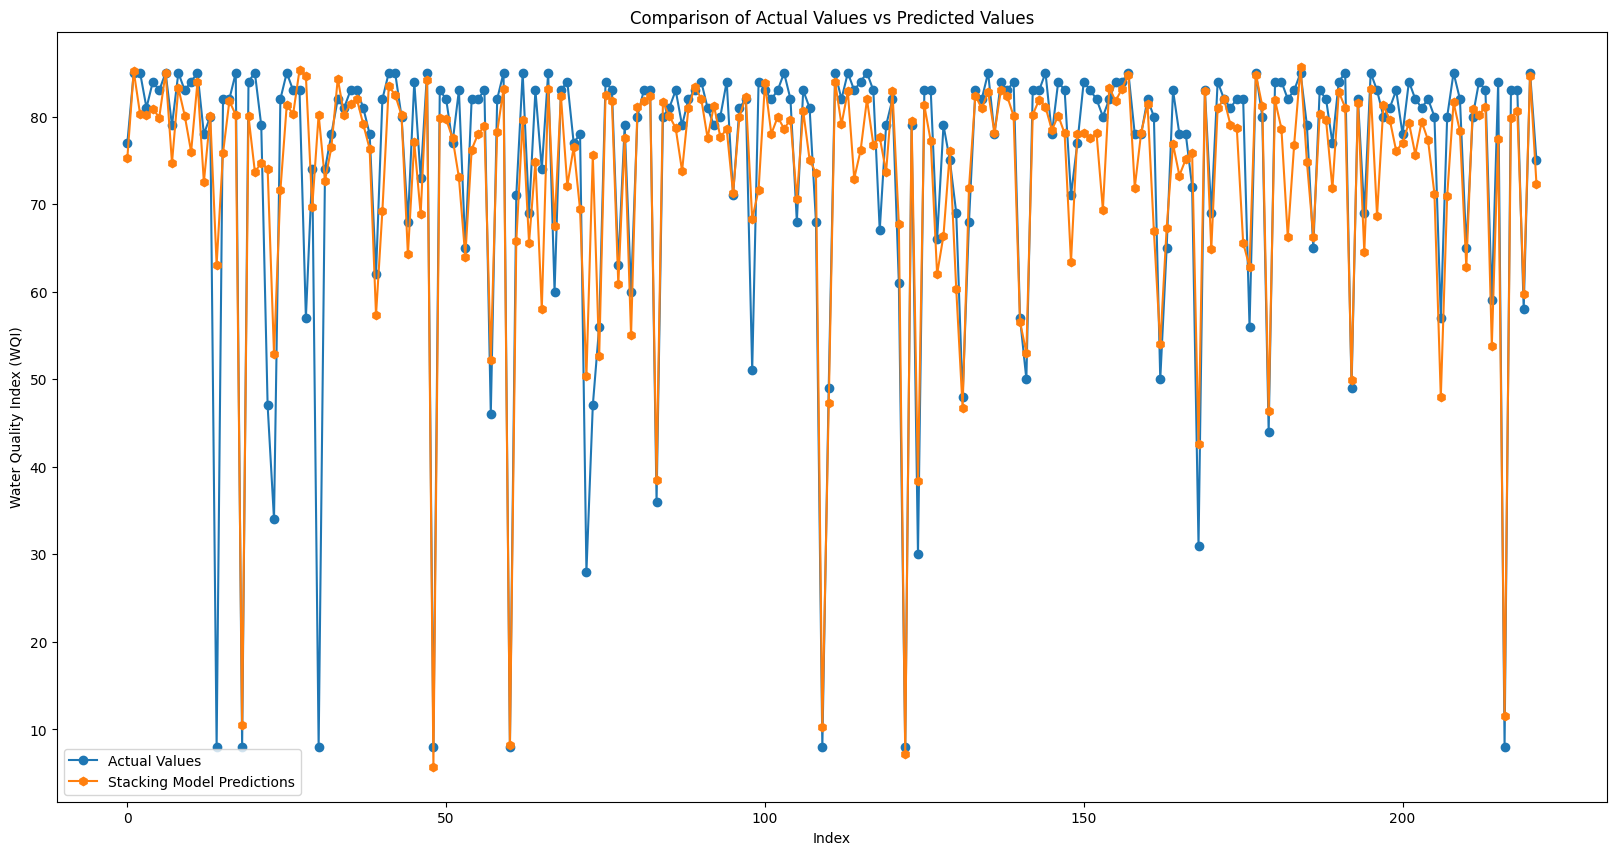

In [ ]:
plt.figure(figsize=(20, 10))
plt.plot(y_test.values, label='Actual Values', marker='o')
plt.plot(sm_pred, label='Stacking Model Predictions', marker='h')
plt.title('Comparison of Actual Values vs Predicted Values')
plt.xlabel('Index')
plt.ylabel('Water Quality Index (WQI)')
plt.legend()
plt.show()

# 5. Feature Importance (10%)


---

Assess the importance of features within your decision tree model. Provide commentary on the reliability of your model's results based on the feature importance scores.

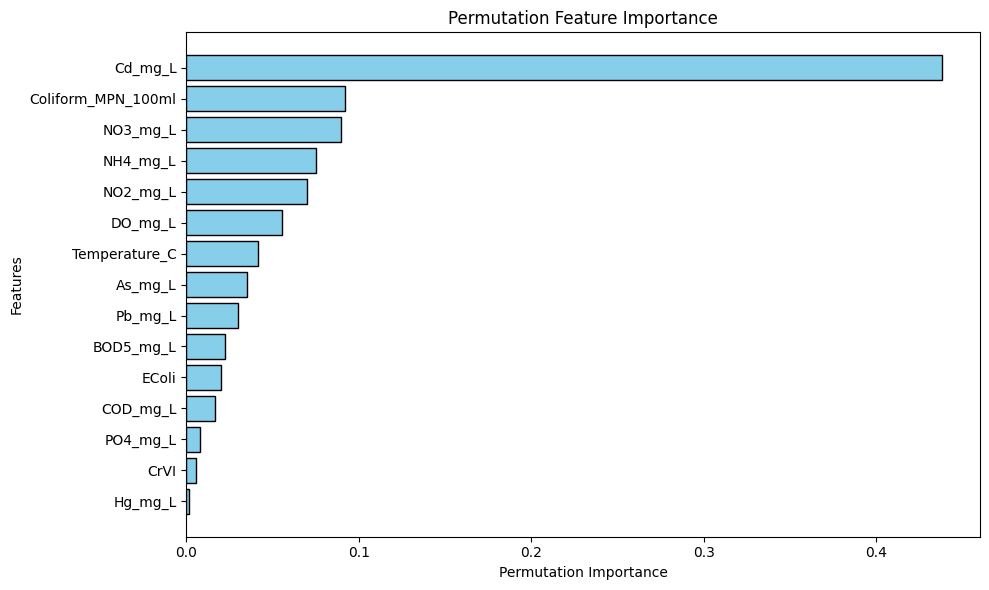

In [ ]:
# Tính Permutation Importance
perm_importance = permutation_importance( stacking_model, X_test, y_test, n_repeats=30, random_state=42 )
# Lấy tên cột thực tế từ DataFrame gốc
feature_names = [ "Temperature_C", "pH", "DO_mg_L", "COD_mg_L", "BOD5_mg_L", "NO3_mg_L",
                 "NO2_mg_L", "NH4_mg_L", "PO4_mg_L", "Coliform_MPN_100ml", "EColi", "As_mg_L",
                  "Hg_mg_L", "Pb_mg_L", "Cd_mg_L", "CrVI" ]
# Sắp xếp theo giá trị importance
sorted_idx = perm_importance.importances_mean.argsort()
# Vẽ biểu đồ
plt.figure(figsize=(10, 6))
plt.barh(np.array(feature_names)[sorted_idx], perm_importance.importances_mean[sorted_idx], color="skyblue", edgecolor="black")
plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()